# 03 — EDA: Univariate Analysis
### Hotel Booking Behavior Segmentation Using Unsupervised Machine Learning

**CRISP-ML(Q) Phase:** Phase 2 — Data Preparation (Exploratory Data Analysis)

**Project stage:** 3 of 16 — builds on Notebook 02's cleaned dataset

---

## 1. Objective

This notebook examines **one variable at a time** across the candidate behavioral features, before we ever look at relationships between variables (Notebook 04) or think about outlier treatment (Notebook 05).

For every numeric candidate feature we will produce:
- A histogram with a KDE (kernel density estimate) curve, to see the overall shape of the distribution.
- A boxplot, to see the spread, median, and presence of extreme values at a glance.
- Descriptive statistics and skewness.

For key categorical variables we will produce frequency tables and count plots.

**Why this matters for clustering specifically:** distance-based clustering algorithms (which we'll use starting in Notebook 08) are sensitive to the *shape* of each feature's distribution — a heavily skewed or zero-inflated feature can dominate distance calculations unless it's scaled or transformed appropriately later (Notebook 07). Understanding these shapes now is what will let us make an informed scaling/transformation decision later, instead of guessing.

## 2. Business Context

Each of these variables represents a specific piece of booking behavior the hotel already collects but has never systematically looked at in aggregate:

- **Timing behavior** (`lead_time`) — how far ahead guests plan.
- **Stay behavior** (`stays_in_weekend_nights`, `stays_in_week_nights`) — how long and what kind of stay.
- **Party composition** (`adults`, `children`, `babies`) — who is traveling.
- **Engagement/service behavior** (`booking_changes`, `total_of_special_requests`, `required_car_parking_spaces`) — how much the guest interacts with or asks of the hotel.
- **Value** (`adr`) — the average daily rate, our best available proxy for booking value.
- **Loyalty signals** (`is_repeated_guest`, `previous_cancellations`, `previous_bookings_not_canceled`) — prior relationship with the hotel, as captured in this data.

Before we can group bookings into meaningful segments, we need to understand what "typical" looks like for each of these individually — otherwise we won't be able to tell what makes a cluster's average lead time or ADR unusually high or low later on.

## 3. Imports

In [1]:
# pandas / numpy: data handling and statistics
import pandas as pd
import numpy as np

# matplotlib / seaborn: visualization
import matplotlib.pyplot as plt
import seaborn as sns

# os: portable file paths
import os


## 4. Configuration

In [2]:
RANDOM_STATE = 42

# Input: the cleaned dataset produced by Notebook 02
CLEANED_DATA_PATH = "../data/processed/02_cleaned_hotel_bookings.csv"

# Outputs of this notebook
FIGURES_DIR = "../reports/figures"
UNIVARIATE_SUMMARY_PATH = "../reports/tables/03_univariate_numeric_summary.csv"

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(os.path.dirname(UNIVARIATE_SUMMARY_PATH), exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

# The 13 primary numeric behavioral candidates named in the project brief.
# We deliberately keep this list explicit (not "all numeric columns") so we
# stay focused on features that are actually relevant to booking behavior.
NUMERIC_CANDIDATES = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "booking_changes",
    "adr",
    "required_car_parking_spaces",
    "total_of_special_requests",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
]

# Key categorical variables we will profile in this notebook.
CATEGORICAL_CANDIDATES = [
    "hotel",
    "meal",
    "market_segment",
    "distribution_channel",
    "deposit_type",
    "customer_type",
    "reserved_room_type",
]


## 5. Analysis / Implementation

### 5.1 Load the Cleaned Data

In [3]:
df = pd.read_csv(CLEANED_DATA_PATH)

print("Loaded shape:", df.shape)


Loaded shape: (87229, 32)


### 5.2 Descriptive Statistics for All Numeric Candidates

In [4]:
numeric_summary = df[NUMERIC_CANDIDATES].describe().T

# Add skewness: a measure of how asymmetric a distribution is.
# Skewness near 0 = roughly symmetric.
# Skewness > 1 (or < -1) = strongly skewed, which matters for scaling decisions later.
numeric_summary["skewness"] = df[NUMERIC_CANDIDATES].skew()

# Add the percentage of rows that are exactly zero - important for features
# like previous_cancellations or required_car_parking_spaces, which are
# mostly zero for the majority of bookings (zero-inflated features).
numeric_summary["pct_zero"] = [
    round((df[col] == 0).mean() * 100, 1) for col in NUMERIC_CANDIDATES
]

numeric_summary = numeric_summary.sort_values("skewness", ascending=False)
numeric_summary.to_csv(UNIVARIATE_SUMMARY_PATH)

numeric_summary


,count,mean,std,min,25%,50%,75%,max,skewness,pct_zero
previous_cancellations,87229.0,0.030403,0.369347,0.0,0.00,0.0,0.0,26.0,34.329456,98.1
babies,87229.0,0.010845,0.113704,0.0,0.00,0.0,0.0,10.0,21.128311,99.0
previous_bookings_not_canceled,87229.0,0.184033,1.733033,0.0,0.00,0.0,0.0,72.0,20.456047,95.9
adults,87229.0,1.879364,0.621727,0.0,2.00,2.0,2.0,55.0,20.394419,0.3
adr,87229.0,106.519325,54.890211,0.0,72.25,98.2,134.1,5400.0,11.018648,1.9
booking_changes,87229.0,0.268477,0.710612,0.0,0.00,0.0,0.0,18.0,5.069509,81.9
is_repeated_guest,87229.0,0.038554,0.192530,0.0,0.00,0.0,0.0,1.0,4.793615,96.1
required_car_parking_spaces,87229.0,0.084307,0.281660,0.0,0.00,0.0,0.0,8.0,3.488641,91.6
children,87229.0,0.138899,0.456267,0.0,0.00,0.0,0.0,10.0,3.459587,90.4
stays_in_week_nights,87229.0,2.623887,2.039810,0.0,1.00,2.0,4.0,50.0,2.575562,7.0


**What this code does:** computes standard descriptive statistics, adds skewness (distribution asymmetry) and the percentage of exactly-zero values for every numeric candidate feature.

**Why it's required:** these three numbers together — spread, skewness, and zero-inflation — tell us more about how a feature will behave in distance-based clustering than the mean or median alone.

**What to look for:** skewness values well above 1 indicate a long right tail (a small number of unusually large values pulling the distribution). A high `pct_zero` combined with high skewness (for example `previous_cancellations`, `babies`) tells us the feature is dominated by a single value for almost every booking, with a small population of bookings behaving very differently.

**Findings (from the actual computed table above):**

- `previous_cancellations` is the most skewed feature (skewness ≈ 34) and is zero for 98.1% of bookings — almost every booking has no prior cancellation history, but a small number of bookings have many.
- `babies` (skewness ≈ 21, 99.0% zero), `previous_bookings_not_canceled` (skewness ≈ 20, 95.9% zero), and `adults` (skewness ≈ 20, but only 0.3% zero — its skew comes from a handful of very large group bookings, not zero-inflation) are all heavily skewed for different underlying reasons, which is an important distinction: not every skewed feature is skewed for the same reason.
- `adr` is also notably skewed (skewness ≈ 11) — most bookings cluster in a normal price range, with a long tail of high-value bookings (already partly investigated in Notebook 02).
- `lead_time`, `stays_in_weekend_nights`, `stays_in_week_nights`, and `total_of_special_requests` show more moderate skew (roughly 1–2.6) — still right-skewed, but less extreme.
- `is_repeated_guest`, `required_car_parking_spaces`, `booking_changes`, and `children` are dominated by zero (82–96% zero), consistent with these representing behaviors that most bookings simply don't exhibit.

**Business interpretation:** most guests are booking in a fairly "default" way — first-time guest, no changes, no parking request, no children — while a meaningful minority engage in every one of these behaviors more heavily. This pattern is exactly the kind of structure clustering is well-suited to separate out, *if* we scale/transform these features appropriately (Notebook 07) so that the heavy skew doesn't let one or two features dominate the distance calculations.

### 5.3 Numeric Variables — Distribution Shape (Histogram + KDE + Boxplot)

For each numeric feature we plot a histogram with a KDE curve (to see the overall shape) next to a boxplot (to see the median, interquartile range, and extreme values at a glance).

**A note on the histogram x-axis:** several of these features have a small number of extreme values that would compress the rest of the histogram into an unreadable sliver if the x-axis showed the full range. For readability only, the histogram x-axis is capped at the 99th percentile of each feature; the *boxplot next to it always shows the true full range*, including anything beyond that cap. No data is removed or altered here — this is a visualization choice only, made explicit in each chart's subtitle.

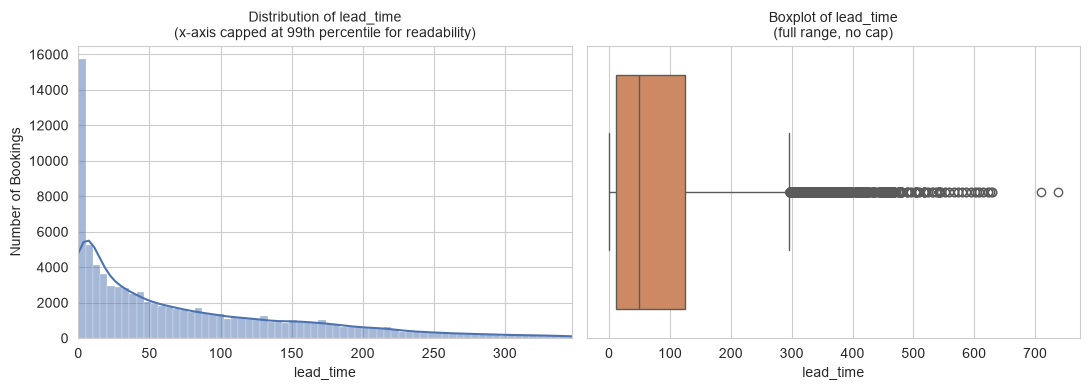

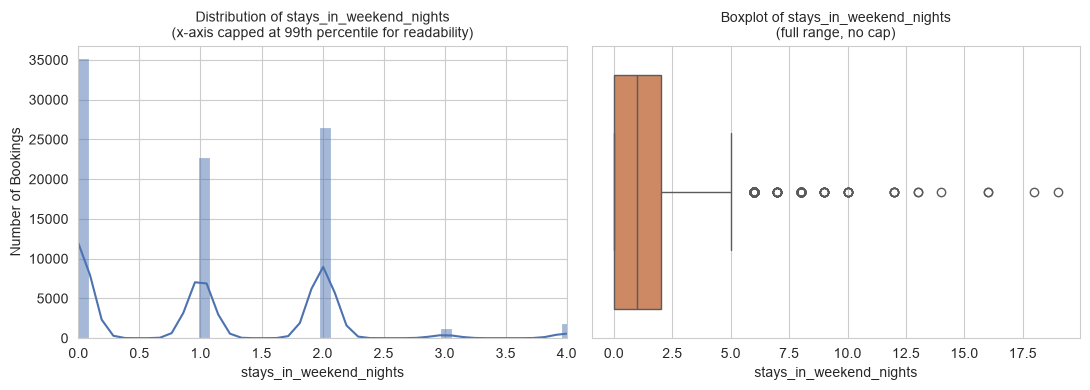

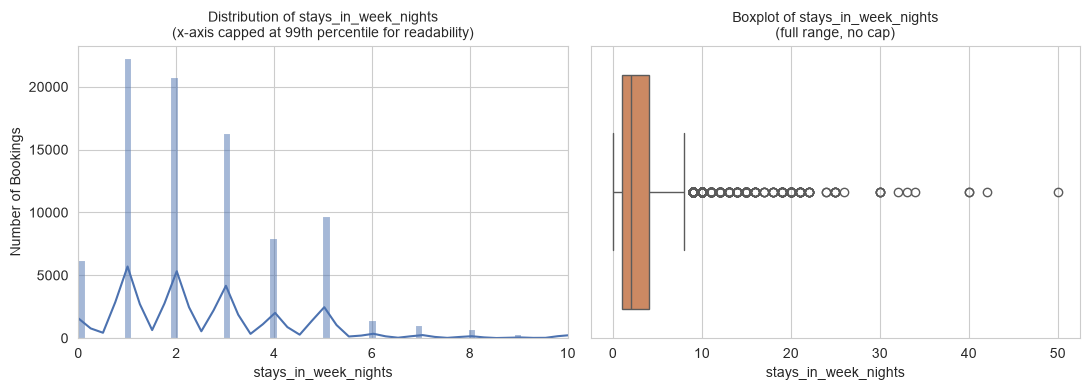

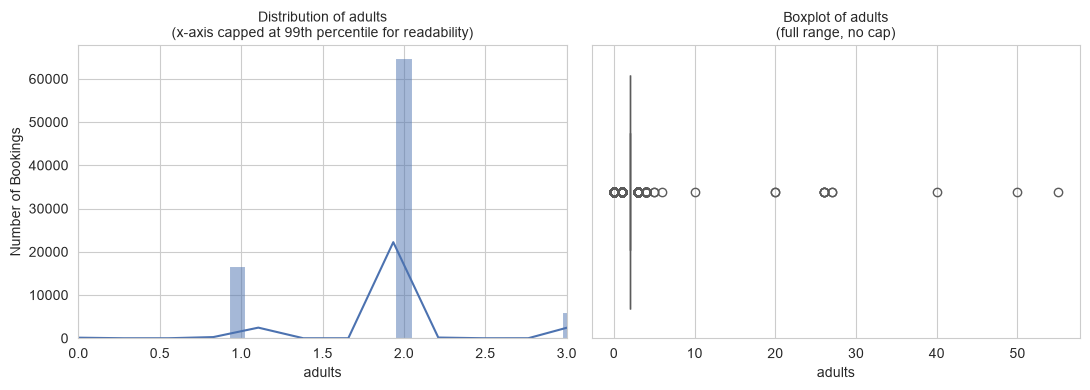

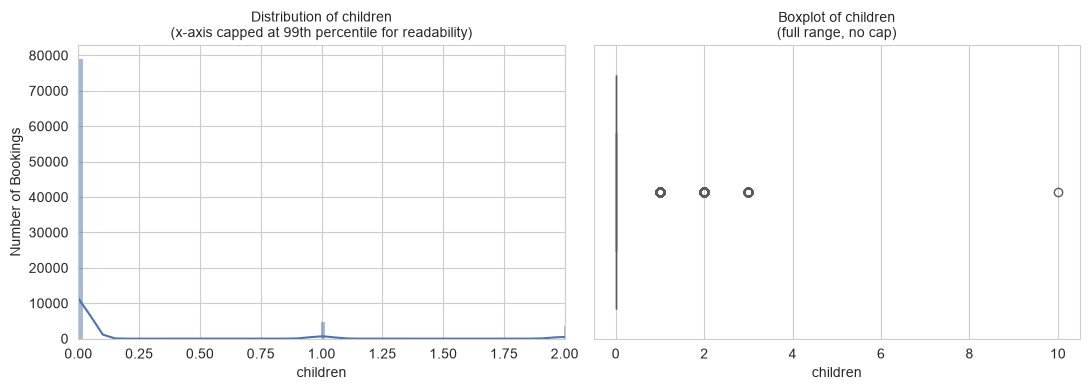

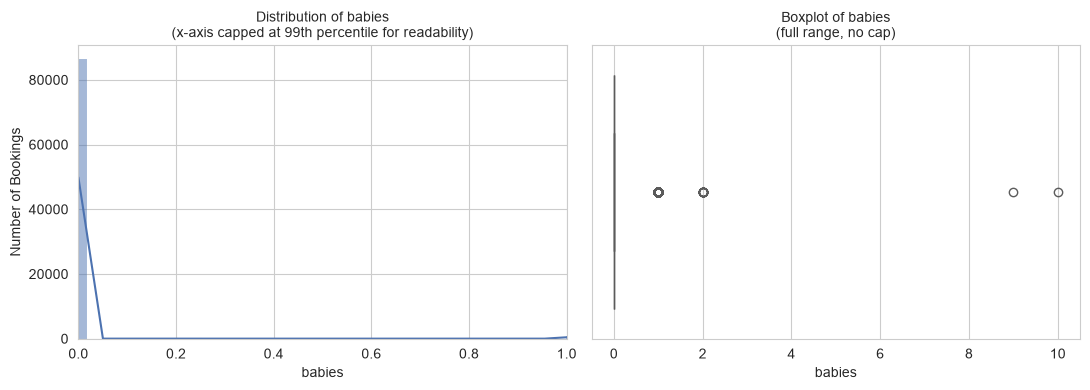

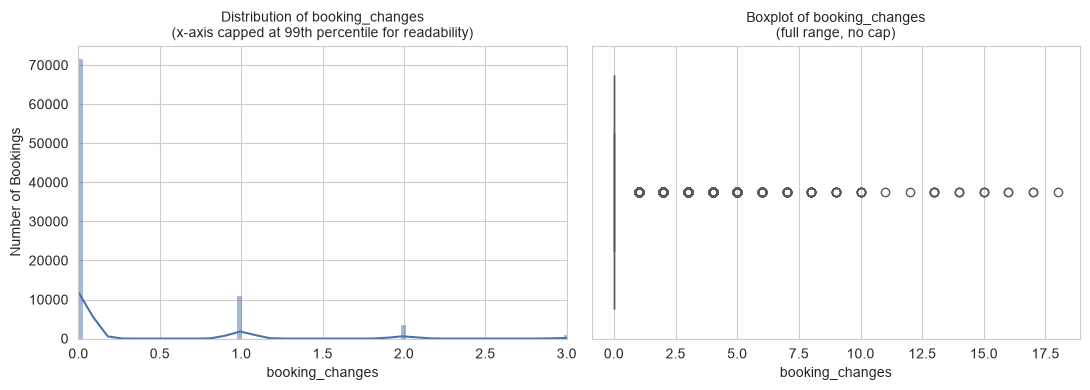

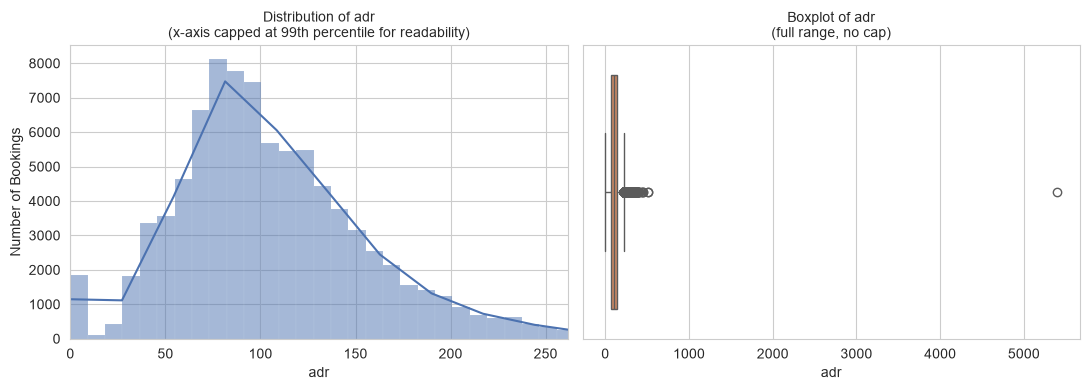

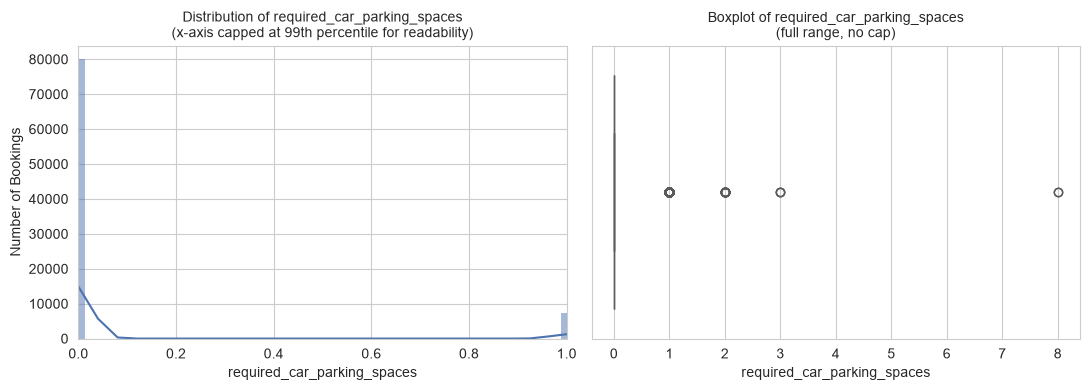

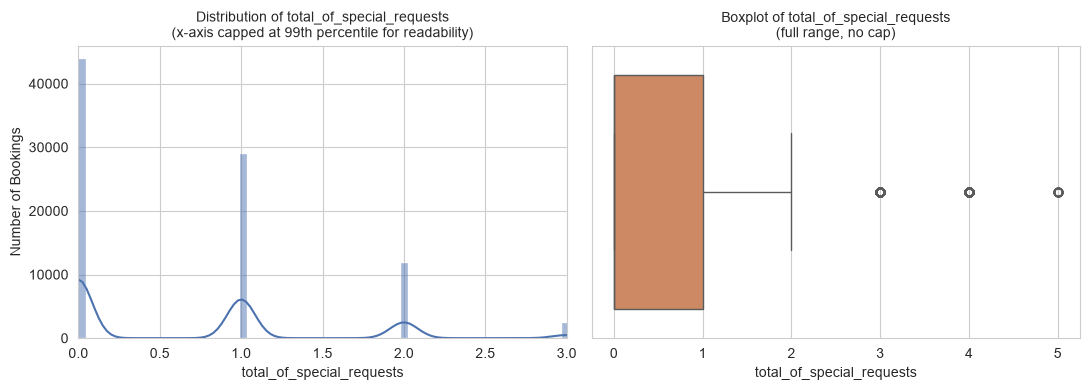

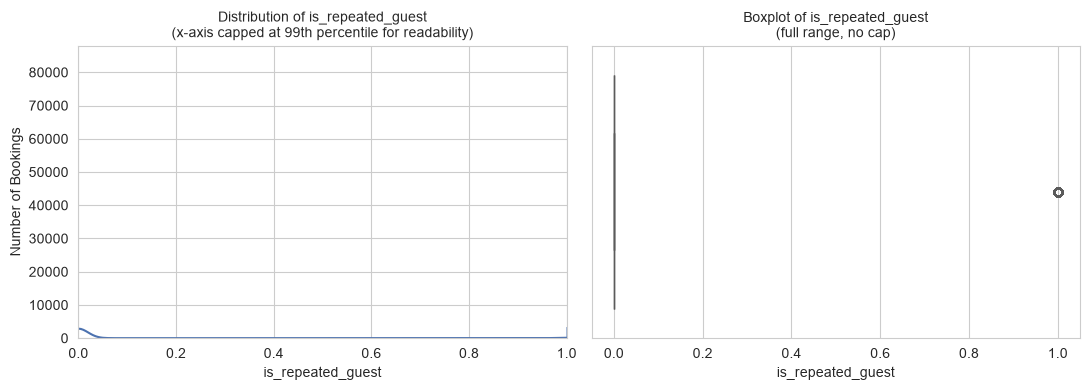

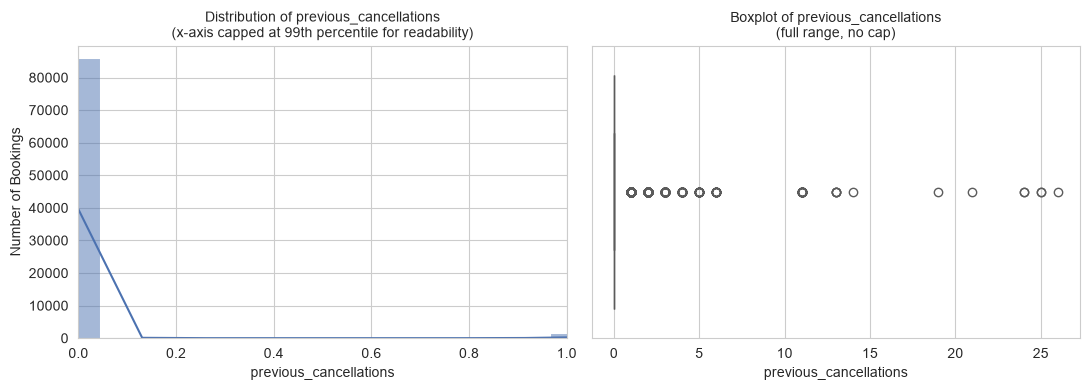

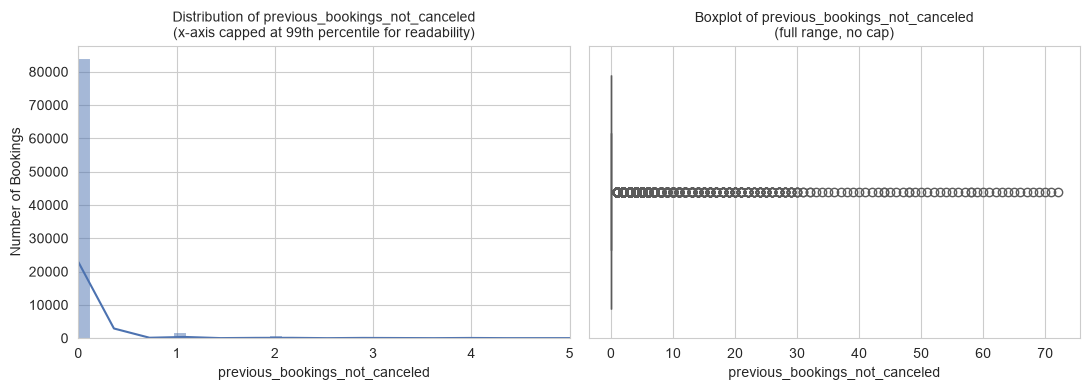

In [5]:
def plot_univariate_numeric(data, column, figures_dir):
    """
    Plot a histogram+KDE and a boxplot side by side for one numeric column,
    and save the figure. The histogram's x-axis is capped at the column's
    99th percentile purely for visual readability; the boxplot is never
    capped, so it still shows the true extreme values.
    """
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    # --- Histogram + KDE (left panel) ---
    cap_value = data[column].quantile(0.99)

    sns.histplot(data=data, x=column, kde=True, ax=axes[0], color="#4C72B0")
    axes[0].set_xlim(left=data[column].min(), right=cap_value)
    axes[0].set_title(f"Distribution of {column}\n(x-axis capped at 99th percentile for readability)", fontsize=10)
    axes[0].set_xlabel(column)
    axes[0].set_ylabel("Number of Bookings")

    # --- Boxplot (right panel) - always shows the true, full range ---
    sns.boxplot(data=data, x=column, ax=axes[1], color="#DD8452")
    axes[1].set_title(f"Boxplot of {column}\n(full range, no cap)", fontsize=10)
    axes[1].set_xlabel(column)

    plt.tight_layout()
    plt.savefig(os.path.join(figures_dir, f"03_univariate_{column}.png"))
    plt.show()


# Run this for every numeric candidate feature.
for numeric_column in NUMERIC_CANDIDATES:
    plot_univariate_numeric(df, numeric_column, FIGURES_DIR)


**Findings, variable by variable (grounded in the descriptive table above):**

- **`lead_time`** — median 49 days, mean ≈ 80 days; right-skewed with a long tail out to 737 days. Most bookings are made weeks to a few months ahead, with a real subpopulation of very early planners.
- **`stays_in_weekend_nights`** — 40.2% of bookings include zero weekend nights; median is 1 night. Many bookings are weekday-only (consistent with business/city travel).
- **`stays_in_week_nights`** — median 2 nights, mean ≈ 2.6; more spread than weekend nights, with some long-stay bookings pulling the tail out to 50 nights.
- **`adults`** — overwhelmingly concentrated at 2 (median and mode), consistent with couples/pairs being the dominant booking type; the tail toward large values reflects rare large-group bookings, not zero-inflation.
- **`children`** — 90.4% zero; the "typical" booking has no children, but a real minority are family bookings.
- **`babies`** — 99.0% zero; babies-on-booking is a rare but real behavior worth checking whether it clusters with any other pattern (Notebook 04).
- **`booking_changes`** — 81.9% zero; most bookings are made once and never amended, but a meaningful ~18% show at least one change.
- **`adr`** — median ≈ €98, mean ≈ €107; right-skewed with the extreme high values already investigated for legitimacy in Notebook 02.
- **`required_car_parking_spaces`** — 91.6% zero; a clear minority-behavior feature, likely to be a useful distinguishing signal for exactly that minority.
- **`total_of_special_requests`** — 50.2% zero; roughly an even split between guests who make no special requests and those who make at least one.
- **`is_repeated_guest`** — 96.1% zero, i.e. only about 3.9% of bookings in this data are flagged as repeat guests. This sets clear expectations for Notebook 04/13: any cluster we later call "loyal" will necessarily be a **minority** of total bookings, because repeat-guest bookings are rare in this dataset overall.
- **`previous_cancellations`** and **`previous_bookings_not_canceled`** — both over 95% zero; most bookings in this data have no visible prior history in these two fields (consistent with the `is_repeated_guest` finding and the data limitation already noted in Notebook 01).

### 5.4 Categorical Variables — Frequency Tables and Count Plots

In [6]:
for categorical_column in CATEGORICAL_CANDIDATES:
    print(f"--- {categorical_column} ---")
    counts = df[categorical_column].value_counts()
    percentages = (counts / len(df) * 100).round(1)
    freq_table = pd.DataFrame({"count": counts, "pct": percentages})
    print(freq_table)
    print()


--- hotel ---
              count   pct
hotel                    
City Hotel    53274  61.1
Resort Hotel  33955  38.9

--- meal ---
           count   pct
meal                  
BB         67906  77.8
SC          9391  10.8
HB          9080  10.4
Undefined    492   0.6
FB           360   0.4

--- market_segment ---
                count   pct
market_segment             
Online TA       51553  59.1
Offline TA/TO   13855  15.9
Direct          11780  13.5
Groups           4921   5.6
Corporate        4200   4.8
Complementary     692   0.8
Aviation          226   0.3
Undefined           2   0.0

--- distribution_channel ---
                      count   pct
distribution_channel             
TA/TO                 69028  79.1
Direct                12953  14.8
Corporate              5062   5.8
GDS                     181   0.2
Undefined                 5   0.0

--- deposit_type ---
              count   pct
deposit_type             
No Deposit    86084  98.7
Non Refund     1038   1.2
Refundabl

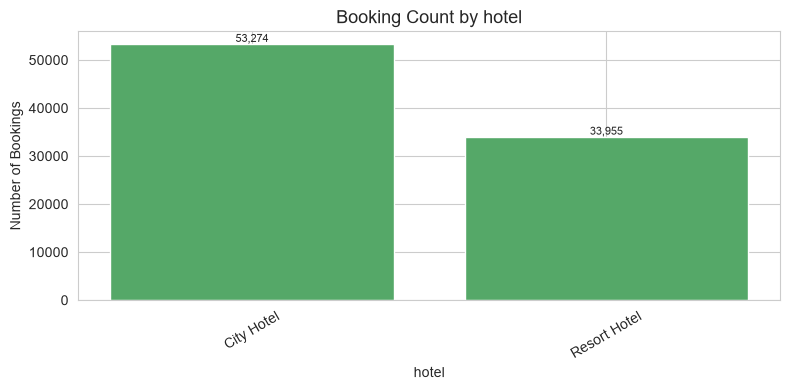

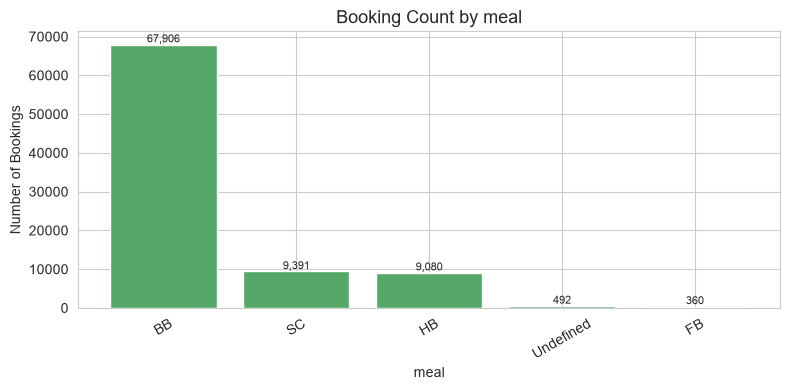

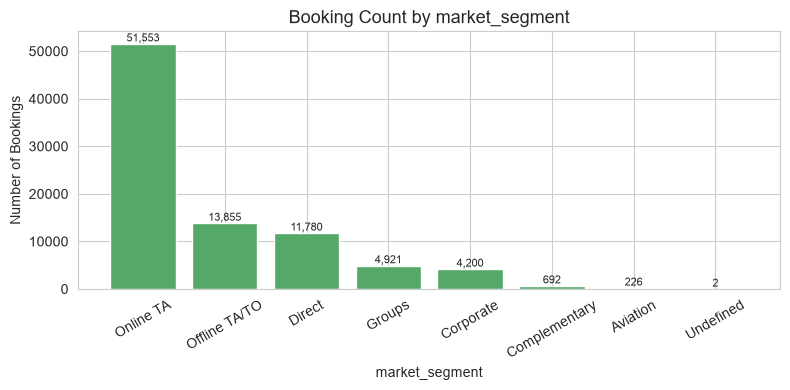

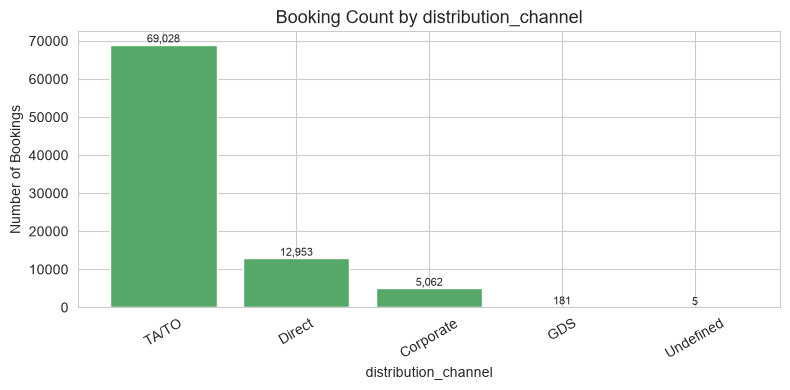

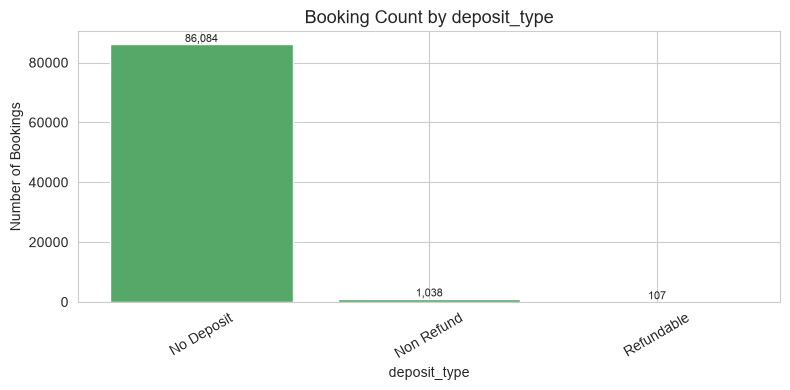

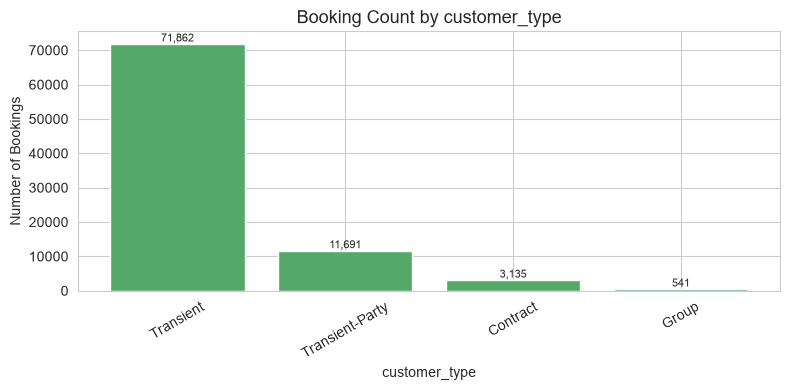

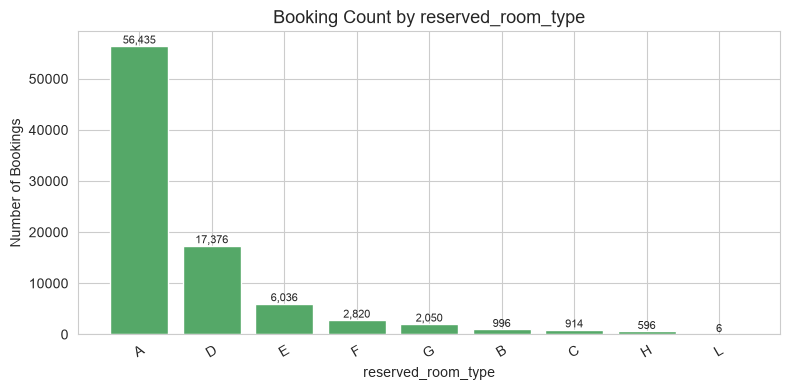

In [7]:
def plot_categorical_countplot(data, column, figures_dir, top_n=10):
    """
    Plot a count plot for a categorical column, ordered from most to least
    frequent. If a column has more than top_n categories, only the top_n
    are shown, to keep the chart readable.
    """
    counts = data[column].value_counts().head(top_n)

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(counts.index.astype(str), counts.values, color="#55A868")

    ax.set_title(f"Booking Count by {column}", fontsize=13)
    ax.set_xlabel(column)
    ax.set_ylabel("Number of Bookings")
    ax.tick_params(axis="x", rotation=30)

    for i, value in enumerate(counts.values):
        ax.text(i, value, f"{value:,}", ha="center", va="bottom", fontsize=8)

    plt.tight_layout()
    plt.savefig(os.path.join(figures_dir, f"03_countplot_{column}.png"))
    plt.show()


for categorical_column in CATEGORICAL_CANDIDATES:
    plot_categorical_countplot(df, categorical_column, FIGURES_DIR)


**Findings (from the actual computed tables/charts above):**

- **`hotel`** — City Hotel accounts for 61.1% of bookings, Resort Hotel 38.9%. Any cluster profiling later should check whether it's picking up genuine behavioral differences or largely reflecting this property split.
- **`meal`** — Bed & Breakfast (`BB`) dominates at 77.8%; `Undefined` (492 rows) remains its own category as decided in Notebook 02.
- **`market_segment`** — Online Travel Agency (`Online TA`) is the largest single channel at 59.1%, far ahead of any other segment; `Groups` and `Corporate` are both under 6%.
- **`distribution_channel`** — Travel Agent/Tour Operator (`TA/TO`) dominates at 79.1%, consistent with the `market_segment` picture above (the two fields are related but not identical).
- **`deposit_type`** — `No Deposit` accounts for 98.7% of bookings; `Non Refund` and `Refundable` are both small minorities. This field has very low variance overall and will need a specific justification if used as a clustering input (assessed in Notebook 06).
- **`customer_type`** — `Transient` (individual, non-group/contract bookings) dominates at 82.4%.
- **`reserved_room_type`** — Room type `A` is the most common by far (64.7%), consistent with it likely being the hotel's standard/default room category.

### 5.5 A Data Curiosity Surfaced During EDA

In [8]:
# While reviewing the party-composition variables, check for bookings with
# zero adults but at least one child or baby - i.e. minors traveling with
# no adult on the same booking record. Notebook 02 only removed rows where
# ALL guest counts (adults + children + babies) were zero; this is a
# different, narrower edge case that EDA has now surfaced.
zero_adult_with_minors = df[(df["adults"] == 0) & ((df["children"] > 0) | (df["babies"] > 0))]

print("Bookings with 0 adults but at least one child/baby:", len(zero_adult_with_minors))
print("Percentage of all bookings:", round(len(zero_adult_with_minors) / len(df) * 100, 3), "%")
print()
print(zero_adult_with_minors["reservation_status"].value_counts())


Bookings with 0 adults but at least one child/baby: 219
Percentage of all bookings: 0.251 %

reservation_status
Check-Out    138
Canceled      78
No-Show        3
Name: count, dtype: int64


**Finding:** a small number of bookings show zero adults but at least one child or baby — a combination that is not logically plausible as an actual hotel stay (minors are not booked and hosted without an accompanying adult on the same reservation). This is very likely a data entry pattern where the adult count was recorded as 0 by mistake, rather than a genuine unaccompanied-minor booking.

**Decision:** this is **not treated as data cleaning in this notebook** (EDA notebooks investigate; Notebook 02 already closed its cleaning pass). This finding is flagged here and carried forward as a documented, evidence-based case to revisit during feature engineering (Notebook 06), where we can decide — with the full context of the feature set being finalized — whether to exclude these rows, treat them as a data quality flag, or leave them given their very small share of the data.

## 7. Findings

- Almost every numeric behavioral feature is right-skewed to some degree, and several are heavily zero-inflated (`previous_cancellations`, `babies`, `required_car_parking_spaces`, `is_repeated_guest`, `booking_changes`). This has a direct, practical consequence for Notebook 07: **StandardScaler** (which assumes roughly normal, non-skewed data) may not be the best default choice for every feature — **RobustScaler** and/or log-style transforms are strong candidates to compare there.
- `adults` is skewed for a different reason than most of the other features — a handful of very large group bookings, not zero-inflation — meaning it needs to be evaluated on its own terms rather than lumped in with the zero-inflated group.
- Repeat-guest behavior (`is_repeated_guest`, and by extension `previous_cancellations`/`previous_bookings_not_canceled`) is genuinely rare in this dataset (roughly 4% of bookings), which sets a realistic expectation for cluster sizes later — a "loyal guest" cluster, if one emerges, will necessarily be a minority segment.
- Several categorical features (`deposit_type`, and to a lesser extent `meal`) are dominated by a single category (over 98% and 78% respectively), which limits how much distinguishing information they can realistically contribute to clustering — this will be assessed formally with variance/relevance criteria in Notebook 06.
- EDA surfaced a small, previously undetected data curiosity (zero-adult bookings with children/babies present) that will be carried forward as a documented open item rather than silently fixed here.

## 8. Business Interpretation

The overall picture from this notebook is a hotel business dominated by a fairly narrow "default" booking profile — two adults, booked through an online travel agency, no special requests, no prior history with the hotel — with several distinct minority behaviors layered on top of it: families (children present), service-heavy guests (special requests, parking), change-prone guests (booking modifications), and a small loyal-guest base.

This is a useful early signal for the segmentation project: the interesting, actionable segments are likely to come from *how these minority behaviors combine*, not from the "default" majority alone. This is exactly what the bivariate/multivariate analysis in Notebook 04 will start to explore.

## 9. Conclusion

We examined the distribution of every primary numeric behavioral candidate and every key categorical variable individually, using descriptive statistics, skewness, zero-inflation rates, histograms, boxplots, and count plots. The dataset shows a fairly typical "default" booking profile alongside several right-skewed, zero-inflated minority behaviors — a pattern that will directly inform both feature engineering (Notebook 06) and scaling choices (Notebook 07).

**Next notebook (04 — EDA Bivariate/Multivariate Analysis):** we move from looking at variables one at a time to looking at how they relate to each other — lead time vs. ADR, market segment vs. ADR, repeat-guest status vs. behavior, and a correlation heatmap across the full numeric feature set — to start building a picture of how these behaviors combine.